# Remote AWS Pilot: Hanging-Sphere Convergence @ 512^3

Drives `05_local_stiffness_convergence.ipynb`'s solve pipeline on your two-GPU
AWS instance, split as:

- **GPU 0**: resolution **512** only (the new finest/reference resolution)
- **GPU 1**: the rest of the schedule, **8, 16, 32, 64, 128, 256**

This notebook runs *locally* (wherever you have `ssh`/`scp` on PATH -- Windows
OpenSSH is fine) and never computes anything itself; it deploys
`run_study.py` to the instance and launches two backgrounded processes over
SSH, one per GPU, then lets you poll status and pull results back whenever
you like.

**Run the cells in order once**, then re-run the "status" cell as often as
you want -- it's read-only and safe to spam.


In [1]:
from pathlib import Path

SSH_KEY = r"C:\Users\z0058p1u\.ssh\ibm_learning.pem"
SSH_HOST = "ubuntu@Sketch2Sim-cb7cf3a7878c4a07.elb.us-east-2.amazonaws.com"

REMOTE_REPO_ROOT = "~/cutcell-training"
REMOTE_PYTHON = "~/cutcell-training/.venv/bin/python"

REMOTE_RUN_DIR = f"{REMOTE_REPO_ROOT}/aws_pilot_512"

LOCAL_SCRATCH = Path("./aws_pilot_scratch").resolve()
LOCAL_RESULTS_DIR = Path("./aws_pilot_results").resolve()

LOCAL_SCRATCH.mkdir(parents=True, exist_ok=True)
LOCAL_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

FULL_SCHEDULE = (4, 8, 16, 32, 64, 128, 256)
REFERENCE_RESOLUTION = 256

JOBS = {
    "gpu0_512": {
        "cuda_device": "0",
        "resolutions": (256,),
        "frameworks": ("naive", "weighted", "queso", "nn"),
    },
    "gpu1_rest": {
        "cuda_device": "1",
        "resolutions": (4, 8, 16, 32, 64, 128,),
        "frameworks": ("naive", "weighted", "queso", "nn"),
    },
}

SUPPORT_MODE = "smooth_foundation"

print("Jobs configured:")
for name, job in JOBS.items():
    print(f"  {name}: GPU {job['cuda_device']}, resolutions={job['resolutions']}, frameworks={job['frameworks']}")

Jobs configured:
  gpu0_512: GPU 0, resolutions=(256,), frameworks=('naive', 'weighted', 'queso', 'nn')
  gpu1_rest: GPU 1, resolutions=(4, 8, 16, 32, 64, 128), frameworks=('naive', 'weighted', 'queso', 'nn')


## 1. Diagnose the instance

Run this once before touching anything else. It tells you whether the repo,
QuESo build, and a CUDA-capable torch are already in place, and how much
RAM/VRAM you actually have to work with at 512^3 (the domain has ~135M grid
nodes at that resolution -- worth knowing your headroom before launching a
multi-hour job).


In [2]:
# --- Cell 2: SSH/SCP helpers ------------------------------------------------
import subprocess

def run_remote(command, check=True, timeout=120):
    """Run `command` on the remote host and return (returncode, stdout, stderr)."""
    full_cmd = ["ssh", "-i", SSH_KEY, SSH_HOST, command]
    result = subprocess.run(full_cmd, capture_output=True, text=True, timeout=timeout)
    print(result.stdout)
    if result.stderr.strip():
        print("[stderr]", result.stderr)
    if check and result.returncode != 0:
        raise RuntimeError(f"Remote command failed (exit {result.returncode}): {command}")
    return result.returncode, result.stdout, result.stderr


def copy_to_remote(local_path, remote_path):
    subprocess.run(["scp", "-i", SSH_KEY, str(local_path), f"{SSH_HOST}:{remote_path}"], check=True)


def copy_dir_from_remote(remote_path, local_path):
    Path(local_path).mkdir(parents=True, exist_ok=True)
    subprocess.run(["scp", "-i", SSH_KEY, "-r", f"{SSH_HOST}:{remote_path}", str(local_path)], check=True)


print("SSH helpers ready.")


SSH helpers ready.


In [3]:
run_remote(
    f"{REMOTE_PYTHON} -c "
    "\"import sys, numpy, pandas, torch; "
    "print('Python:', sys.executable); "
    "print('NumPy:', numpy.__version__); "
    "print('pandas:', pandas.__version__); "
    "print('PyTorch:', torch.__version__); "
    "print('CUDA:', torch.cuda.is_available()); "
    "print('GPU count:', torch.cuda.device_count()); "
    "print([torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])\""
)

Python: /home/ubuntu/cutcell-training/.venv/bin/python
NumPy: 2.4.4
pandas: 3.0.2
PyTorch: 2.11.0+cu128
CUDA: True
GPU count: 2
['NVIDIA RTX PRO 6000 Blackwell Server Edition', 'NVIDIA RTX PRO 6000 Blackwell Server Edition']



(0,
 "Python: /home/ubuntu/cutcell-training/.venv/bin/python\nNumPy: 2.4.4\npandas: 3.0.2\nPyTorch: 2.11.0+cu128\nCUDA: True\nGPU count: 2\n['NVIDIA RTX PRO 6000 Blackwell Server Edition', 'NVIDIA RTX PRO 6000 Blackwell Server Edition']\n",
 '')

In [4]:
# --- Cell 3: instance diagnostics -------------------------------------------

diagnostic_script = r"""
echo '--- Current directory ---'; pwd
echo '--- Home directory ---'; echo $HOME
echo '--- GPUs ---'; nvidia-smi --query-gpu=index,name,memory.total,memory.used,driver_version --format=csv
echo '--- CPU/RAM ---'; nproc; free -h
echo '--- Disk (home) ---'; df -h ~
echo '--- repo candidates ---'; find ~ -maxdepth 5 -type d -name 'clean_simulation' 2>/dev/null
echo '--- QuESo build candidates ---'; find ~ -maxdepth 6 -iname 'QuESo' 2>/dev/null
echo '--- python/conda ---'; which python3; which conda; conda env list 2>/dev/null
echo '--- torch/cuda (default python3) ---'; python3 -c "import torch; print(torch.__version__, torch.cuda.is_available(), torch.cuda.device_count()); print([torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())] if torch.cuda.is_available() else [])" 2>&1
echo '--- tmux/screen ---'; which tmux; which screen
"""

run_remote(diagnostic_script)

--- Current directory ---
/home/ubuntu
--- Home directory ---
/home/ubuntu
--- GPUs ---
index, name, memory.total [MiB], memory.used [MiB], driver_version
0, NVIDIA RTX PRO 6000 Blackwell Server Edition, 97887 MiB, 0 MiB, 595.71.05
1, NVIDIA RTX PRO 6000 Blackwell Server Edition, 97887 MiB, 0 MiB, 595.71.05
--- CPU/RAM ---
48
               total        used        free      shared  buff/cache   available
Mem:           499Gi        12Gi       488Gi       3.2Mi       1.9Gi       486Gi
Swap:             0B          0B          0B
--- Disk (home) ---
Filesystem      Size  Used Avail Use% Mounted on
/dev/root       968G  158G  810G  17% /
--- repo candidates ---
/home/ubuntu/cutcell-training/clean_simulation
--- QuESo build candidates ---
/home/ubuntu/cutcell-training/QuESo
/home/ubuntu/cutcell-training/QuESo/queso
/home/ubuntu/cutcell-training/QuESo/out/build/linux/queso
/home/ubuntu/cutcell-training/clean_simulation/queso
--- python/conda ---
/usr/bin/python3
--- torch/cuda (default pyt

(0,
 '--- Current directory ---\n/home/ubuntu\n--- Home directory ---\n/home/ubuntu\n--- GPUs ---\nindex, name, memory.total [MiB], memory.used [MiB], driver_version\n0, NVIDIA RTX PRO 6000 Blackwell Server Edition, 97887 MiB, 0 MiB, 595.71.05\n1, NVIDIA RTX PRO 6000 Blackwell Server Edition, 97887 MiB, 0 MiB, 595.71.05\n--- CPU/RAM ---\n48\n               total        used        free      shared  buff/cache   available\nMem:           499Gi        12Gi       488Gi       3.2Mi       1.9Gi       486Gi\nSwap:             0B          0B          0B\n--- Disk (home) ---\nFilesystem      Size  Used Avail Use% Mounted on\n/dev/root       968G  158G  810G  17% /\n--- repo candidates ---\n/home/ubuntu/cutcell-training/clean_simulation\n--- QuESo build candidates ---\n/home/ubuntu/cutcell-training/QuESo\n/home/ubuntu/cutcell-training/QuESo/queso\n/home/ubuntu/cutcell-training/QuESo/out/build/linux/queso\n/home/ubuntu/cutcell-training/clean_simulation/queso\n--- python/conda ---\n/usr/bin/pytho

In [7]:
result = subprocess.run(
    ["ssh", "-i", SSH_KEY, SSH_HOST, "pwd"],
    capture_output=True,
    text=True
)

print("RETURN CODE:", result.returncode)
print("STDOUT:", result.stdout)
print("STDERR:", result.stderr)

RETURN CODE: 0
STDOUT: /home/ubuntu

STDERR: 


**Stop here and update Cell 1** (`REMOTE_REPO_ROOT`, `REMOTE_PYTHON`) based
on what you saw above. If `clean_simulation` isn't on the box yet, `git clone`
or `scp -r` it over before continuing -- this notebook does not push the
whole repo (checkpoints + QuESo build artifacts are typically too large for a
convenient `scp`); it only deploys the small orchestration script.

Also sanity-check your total RAM against 512^3: `build_hard_constraint_problem`
allocates several full-grid arrays (~134M cells) on the CPU side before QuESo
even runs. If you're on a smaller instance, consider dropping
`HANGING_SPHERE_SURFACE_SUBDIVISIONS` or asking me to help slim that path
down further -- don't launch the 512 job blind if `free -h` above looked
tight (rule of thumb: budget at least ~2-3 KB per active cell across the
several float64 temporaries in play, so tens of GB for the 512 job is a
realistic floor, not a ceiling).


In [5]:
# --- Cell 4: write run_study.py locally, then deploy it ---------------------
# The full script is embedded below so this notebook is self-contained.
RUN_STUDY_PY = r'''
#!/usr/bin/env python3
"""Headless, env-var-driven runner for the hanging-sphere cut-cell convergence study.

This reconstructs the canonical (non-exploratory) cell sequence of
05_local_stiffness_convergence.ipynb -- cells 1, 3, 4, 5, 6, 7, 8, 9, 11, 12 --
as a plain script so it can run unattended on a remote GPU box, and adds
per-solve wall-clock timing that is written incrementally to a CSV so you can
watch progress and pull back timing even from a job that is still running or
that failed partway through.

Designed to be launched twice, once per GPU, e.g.:

    CUDA_VISIBLE_DEVICES=0 HANGING_SPHERE_RESOLUTIONS=512 \
        HANGING_SPHERE_REFERENCE_RESOLUTION=512 python3 run_study.py

    CUDA_VISIBLE_DEVICES=1 HANGING_SPHERE_RESOLUTIONS=8,16,32,64,128,256 \
        HANGING_SPHERE_REFERENCE_RESOLUTION=512 python3 run_study.py

Every environment variable from the original notebook is honored
(HANGING_SPHERE_*). A few new ones were added for the remote/512 run --
search for "NEW:" below.
"""
from __future__ import annotations

import csv
import gc
import json
import os
import sys
import time
import traceback
from pathlib import Path

import numpy as np
import pandas as pd
import torch


def log(message, started_at=None):
    elapsed = '' if started_at is None else f' [{time.perf_counter() - started_at:.1f}s]'
    stamp = time.strftime('%Y-%m-%d %H:%M:%S')
    print(f'[{stamp}] [hanging-sphere] {message}{elapsed}', flush=True)


# --------------------------------------------------------------------------
# Cell 1 + Cell 4: paths, resolution schedule, reference resolution
# --------------------------------------------------------------------------
root = Path.cwd().resolve()
while root != root.parent and not (root / 'clean_simulation').exists():
    root = root.parent
if not (root / 'clean_simulation').exists():
    raise RuntimeError('Run this script from the repository root or a descendant directory.')
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

SUPPORT_OUTPUT_NAMES = {'planar_cap': 'planar_cap_plane_hard_constraints', 'smooth_foundation': 'smooth_foundation'}
OUTPUT_DIR = Path(os.environ.get(
    'HANGING_SPHERE_OUTPUT_DIR',
    root / 'clean_simulation' / 'outputs' / 'sphere_displacement_convergence_aws_512',
)).expanduser().resolve()
SUPPORT_MODE = os.environ.get('HANGING_SPHERE_SUPPORT_MODE', 'smooth_foundation').strip().lower()
if SUPPORT_MODE not in SUPPORT_OUTPUT_NAMES:
    raise ValueError(f'Unknown HANGING_SPHERE_SUPPORT_MODE={SUPPORT_MODE!r}.')
SUPPORT_OUTPUT_DIR = OUTPUT_DIR / SUPPORT_OUTPUT_NAMES[SUPPORT_MODE]
PLANAR_CAP_OUTPUT_DIR = OUTPUT_DIR / SUPPORT_OUTPUT_NAMES['planar_cap']
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SUPPORT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLANAR_CAP_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RESOLUTION_SCHEDULE = tuple(int(value) for value in os.environ.get(
    'HANGING_SPHERE_RESOLUTIONS', '4,8,16,32,64,128,256',
).split(','))
REFERENCE_RESOLUTION = int(os.environ.get(
    'HANGING_SPHERE_REFERENCE_RESOLUTION', str(max(RESOLUTION_SCHEDULE)),
))
# NEW: reference resolution need not be part of THIS process's own schedule
# (e.g. the GPU-1 "rest of the schedule" job references 512 without solving it).
DRY_RUN = os.environ.get('HANGING_SPHERE_DRY_RUN', '0') == '1'
CONTINUE_ON_ERROR = os.environ.get('HANGING_SPHERE_CONTINUE_ON_ERROR', '0') == '1'
ELEMENT_BATCH_SIZE = int(os.environ.get('HANGING_SPHERE_ELEMENT_BATCH_SIZE', '32768'))

log(f'Output directory: {OUTPUT_DIR}')
log(f'Resolution schedule for this process: {RESOLUTION_SCHEDULE}; reference: {REFERENCE_RESOLUTION}^3')
log(f'Support mode: {SUPPORT_MODE}; dry run: {DRY_RUN}; element batch size: {ELEMENT_BATCH_SIZE}')

# --------------------------------------------------------------------------
# Cell 3: runtime / solver configuration
# --------------------------------------------------------------------------
SOLVE_DEVICE = os.environ.get('HANGING_SPHERE_DEVICE', 'cuda' if torch.cuda.is_available() else 'cpu')
CPU_THREADS = int(os.environ.get('HANGING_SPHERE_CPU_THREADS', min(6, os.cpu_count() or 1)))
CG_MAX_ITER = int(os.environ.get('HANGING_SPHERE_CG_MAX_ITER', '4000'))
SOLVE_DTYPE = getattr(torch, os.environ.get('HANGING_SPHERE_DTYPE', 'float32'))
if SOLVE_DEVICE == 'cuda' and not torch.cuda.is_available():
    raise RuntimeError('HANGING_SPHERE_DEVICE=cuda was requested but CUDA is unavailable.')
torch.set_num_threads(CPU_THREADS)
try:
    torch.set_num_interop_threads(1)
except RuntimeError:
    pass

queso_python_path = root / 'QuESo' / 'out' / 'install' / ('win' if os.name == 'nt' else 'linux')
if queso_python_path.exists() and str(queso_python_path) not in sys.path:
    sys.path.insert(0, str(queso_python_path))

from clean_simulation.bootstrap import configure_legacy_imports
configure_legacy_imports(root)
from clean_simulation.case import build_case_from_stl
from clean_simulation.internal_fem_kernel.runtime.assembly_ops import assemble_force_base
from clean_simulation.internal_fem_kernel.runtime.matrix_free import (
    StructuredCompressedMatrixFreeElasticityOperator,
    solve_matrix_free_cg,
)
from clean_simulation.internal_nn_runtime.cutcell_bridge import compute_nn_cutcell_stiffness, prepare_nn_inputs
from clean_simulation.nn_runtime import load_nn_engine
from internal_fem_kernel.assembly.stiffness import StiffnessAssembly
from internal_fem_kernel.core.grid_indexing import active_element_nodes

ALL_FRAMEWORKS = {
    'naive': 'Naive full-cell Gauss',
    'weighted': 'Geometric-volume-fraction weighted Gauss',
    'queso': 'QuESo quadrature',
    'nn': 'NN-cut-cell hybrid',
}
requested_frameworks = tuple(name.strip() for name in os.environ.get(
    'HANGING_SPHERE_FRAMEWORKS', ','.join(ALL_FRAMEWORKS),
).split(',') if name.strip())
unknown_frameworks = set(requested_frameworks) - set(ALL_FRAMEWORKS)
if unknown_frameworks or not requested_frameworks:
    raise ValueError(f'Invalid HANGING_SPHERE_FRAMEWORKS: {requested_frameworks}')
FRAMEWORKS = {name: ALL_FRAMEWORKS[name] for name in requested_frameworks}
NN_CHECKPOINT = Path(os.environ.get(
    'HANGING_SPHERE_NN_CHECKPOINT',
    root / 'clean_simulation' / 'outputs' / 'checkpoints' / 'source_sdf_rebuilt_queso_d10_f1024_all_crystals_10h.pt',
))
SPHERE_OVERRIDES = {
    'grid': {'bounds': [[-9.0, -9.0, -9.0], [9.0, 9.0, 9.0]]},
    'material': {'E': 1.0e6, 'nu': 0.3, 'density': 1.0},
    'integration': {'poly_order': 1, 'gauss_order': 2, 'moment_fitting_residual': 1.0e-8},
    'loads': {'gravity': [0.0, 0.0, -98.1]},
    'bc': {'top_cap_fraction': 0.05, 'constraint_axis': 2, 'constraint_side': 'max'},
}
gpu_name = torch.cuda.get_device_name() if torch.cuda.is_available() else 'n/a'
log(f'Device: {SOLVE_DEVICE} ({gpu_name}); CPU threads: {torch.get_num_threads()}')
log(f'Frameworks: {", ".join(FRAMEWORKS)}')
log(f'NN checkpoint: {NN_CHECKPOINT} (exists: {NN_CHECKPOINT.exists()})')


# --------------------------------------------------------------------------
# Cell 5, 6, 7, 8, 9: shared geometry / quadrature / cache helpers
# --------------------------------------------------------------------------
def active_node_ids(active_cells, resolution):
    cells = np.asarray(active_cells, dtype=np.int64)
    node_side = resolution + 1
    i = cells // (resolution * resolution)
    j = (cells // resolution) % resolution
    k = cells % resolution
    base = (i * node_side + j) * node_side + k
    offsets = np.array((0, node_side * node_side, node_side * node_side + node_side, node_side, 1,
                        node_side * node_side + 1, node_side * node_side + node_side + 1, node_side + 1))
    return np.unique((base[:, None] + offsets).reshape(-1))


def strict_sphere_full_cells(case):
    nx, ny, nz = map(int, case.grid.resolution)
    sphere = case.config.get('sphere', {'center': (0.0, 0.0, 0.0), 'radius': 7.5})
    center = np.asarray(sphere['center'], dtype=np.float64)
    radius_squared = float(sphere['radius']) ** 2
    lower = np.asarray(case.grid.bounds[0], dtype=np.float64)
    spacing = np.asarray((case.grid.dx, case.grid.dy, case.grid.dz), dtype=np.float64)
    y = lower[1] + np.arange(ny + 1) * spacing[1]
    z = lower[2] + np.arange(nz + 1) * spacing[2]
    yy, zz = np.meshgrid(y, z, indexing='ij')
    slabs = []
    for i in range(nx):
        x0 = lower[0] + i * spacing[0]
        x1 = x0 + spacing[0]
        distance_squared = np.maximum((x0 - center[0]) ** 2, (x1 - center[0]) ** 2)
        distance_squared += np.maximum((yy[:-1, :-1] - center[1]) ** 2, (yy[1:, 1:] - center[1]) ** 2)
        distance_squared += np.maximum((zz[:-1, :-1] - center[2]) ** 2, (zz[1:, 1:] - center[2]) ** 2)
        local = np.flatnonzero(distance_squared < radius_squared).astype(np.int64)
        if local.size:
            slabs.append(local + i * ny * nz)
    return torch.from_numpy(np.concatenate(slabs) if slabs else np.empty(0, dtype=np.int64))


def point_cell_indices_and_weights(case, point_mask=None):
    points = torch.as_tensor(np.asarray(case.ips), dtype=torch.float64)
    if point_mask is not None:
        points = points[torch.as_tensor(point_mask, dtype=torch.bool)]
    coordinates = points[:, :3]
    weights = points[:, 3]
    lower = torch.as_tensor(case.grid.bounds[0], dtype=torch.float64)
    upper = torch.as_tensor(case.grid.bounds[1], dtype=torch.float64)
    normalized = coordinates.numel() and bool(torch.all((coordinates >= 0.0) & (coordinates <= 1.0)))
    if normalized:
        coordinates = lower + coordinates * (upper - lower)
        weights = weights * torch.prod(upper - lower)
    resolution = torch.as_tensor(case.grid.resolution, dtype=torch.int64)
    spacing = torch.as_tensor((case.grid.dx, case.grid.dy, case.grid.dz), dtype=torch.float64)
    ijk = torch.floor((coordinates - lower) / spacing).to(torch.int64)
    ijk = torch.minimum(torch.maximum(ijk, torch.zeros_like(ijk)), resolution - 1)
    indices = ijk[:, 0] * (resolution[1] * resolution[2]) + ijk[:, 1] * resolution[2] + ijk[:, 2]
    return indices, weights


def physical_cell_weights(case):
    cell_count = int(np.prod(case.grid.resolution))
    indices, weights = point_cell_indices_and_weights(case)
    if not len(indices):
        return torch.zeros(cell_count, dtype=torch.float64)
    volumes = torch.bincount(indices, weights=weights, minlength=cell_count)
    cell_volume = case.grid.dx * case.grid.dy * case.grid.dz
    return (volumes / cell_volume).clamp(0.0, 1.0)


def independent_sphere_volume_fractions(case, cut_indices, quadrature_order=12, chunk_size=16384):
    dtype = torch.float64
    device = cut_indices.device
    sphere = case.config.get('sphere', {'center': (0.0, 0.0, 0.0), 'radius': 7.5})
    center = torch.as_tensor(sphere['center'], dtype=dtype, device=device)
    radius = float(sphere['radius'])
    radius_squared = radius * radius
    spacing = torch.as_tensor((case.grid.dx, case.grid.dy, case.grid.dz), dtype=dtype, device=device)
    lower = torch.as_tensor(case.grid.bounds[0], dtype=dtype, device=device)
    nx, ny, nz = map(int, case.grid.resolution)
    dx, dy, dz = spacing
    cell_volume = dx * dy * dz
    points_np, weights_np = np.polynomial.legendre.leggauss(quadrature_order)
    points = torch.as_tensor(points_np, dtype=dtype, device=device)
    weights = torch.as_tensor(weights_np, dtype=dtype, device=device)
    gx, gy = torch.meshgrid(points, points, indexing='ij')
    gwx, gwy = torch.meshgrid(weights, weights, indexing='ij')
    gx = gx.reshape(1, -1)
    gy = gy.reshape(1, -1)
    gw = (gwx * gwy).reshape(1, -1)
    n_cells = cut_indices.numel()
    fractions = torch.empty(n_cells, dtype=dtype, device=device)
    for start in range(0, n_cells, chunk_size):
        end = min(start + chunk_size, n_cells)
        indices = cut_indices[start:end].to(torch.int64)
        i = indices // (ny * nz)
        j = (indices // nz) % ny
        k = indices % nz
        ijk = torch.stack((i, j, k), dim=1).to(dtype)
        cell_lower = lower + ijk * spacing
        cell_upper = cell_lower + spacing
        xmin, ymin, zmin = cell_lower[:, 0], cell_lower[:, 1], cell_lower[:, 2]
        xmax, ymax, zmax = cell_upper[:, 0], cell_upper[:, 1], cell_upper[:, 2]
        dmin = torch.where(
            center < cell_lower, cell_lower - center,
            torch.where(center > cell_upper, center - cell_upper, torch.zeros_like(cell_lower)),
        )
        min_dist_squared = torch.sum(dmin * dmin, dim=1)
        outside = min_dist_squared > radius_squared
        dmax = torch.maximum(torch.abs(cell_lower - center), torch.abs(cell_upper - center))
        max_dist_squared = torch.sum(dmax * dmax, dim=1)
        inside = max_dist_squared <= radius_squared
        boundary = ~(outside | inside)
        chunk_fractions = torch.zeros(indices.shape[0], dtype=dtype, device=device)
        chunk_fractions[inside] = 1.0
        boundary_ids = torch.nonzero(boundary, as_tuple=False).flatten()
        if boundary_ids.numel() > 0:
            bxmin, bxmax = xmin[boundary_ids], xmax[boundary_ids]
            bymin, bymax = ymin[boundary_ids], ymax[boundary_ids]
            bzmin, bzmax = zmin[boundary_ids], zmax[boundary_ids]
            x = 0.5 * (bxmax - bxmin)[:, None] * gx + 0.5 * (bxmax + bxmin)[:, None]
            y = 0.5 * (bymax - bymin)[:, None] * gy + 0.5 * (bymax + bymin)[:, None]
            sphere_dx = x - center[0]
            sphere_dy = y - center[1]
            remaining = radius_squared - sphere_dx * sphere_dx - sphere_dy * sphere_dy
            valid = remaining > 0.0
            half_height = torch.sqrt(torch.clamp_min(remaining, 0.0))
            sphere_zmin = center[2] - half_height
            sphere_zmax = center[2] + half_height
            intersection_zmin = torch.maximum(sphere_zmin, bzmin[:, None])
            intersection_zmax = torch.minimum(sphere_zmax, bzmax[:, None])
            z_length = torch.clamp_min(intersection_zmax - intersection_zmin, 0.0)
            z_length = torch.where(valid, z_length, torch.zeros_like(z_length))
            volume = torch.sum(z_length * gw, dim=1)
            volume *= 0.25 * (bxmax - bxmin) * (bymax - bymin)
            boundary_fraction = (volume / cell_volume).clamp(0.0, 1.0)
            chunk_fractions[boundary_ids] = boundary_fraction
        fractions[start:end] = chunk_fractions
    return fractions


def ensure_physical_sphere_stl(work_dir):
    import trimesh
    sphere = SPHERE_OVERRIDES.get('sphere', {'center': (0.0, 0.0, 0.0), 'radius': 7.5})
    center = np.asarray(sphere['center'], dtype=np.float64)
    radius = float(sphere['radius'])
    stl_path = work_dir / 'study_geometry_surface.stl'
    expected_bounds = np.vstack((center - radius, center + radius))
    cache_paths = (work_dir / 'queso_cut_points.npy', work_dir / 'queso_cut_stiffness.pt')
    if stl_path.is_file():
        mesh = trimesh.load(stl_path, force='mesh')
        if np.allclose(mesh.bounds, expected_bounds, atol=1.0e-8, rtol=0.0):
            log(f'Reusing cached physical sphere surface and QuESo artifacts in {work_dir.name}.')
            return stl_path
        if any(path.exists() for path in cache_paths):
            raise RuntimeError(f'{work_dir} has QuESo cache files but surface bounds mismatch.')
    if any(path.exists() for path in cache_paths):
        raise RuntimeError(f'{work_dir} has QuESo cache files without a geometrically valid surface.')
    work_dir.mkdir(parents=True, exist_ok=True)
    subdivisions = int(os.environ.get('HANGING_SPHERE_SURFACE_SUBDIVISIONS', '9'))
    trimesh.creation.icosphere(subdivisions=subdivisions, radius=radius).export(stl_path)
    log(f'Created physical radius-{radius:g} sphere surface with {20 * 4 ** subdivisions:,} faces.')
    return stl_path


def build_hard_constraint_problem(resolution):
    overrides = {**SPHERE_OVERRIDES, 'grid': {**SPHERE_OVERRIDES['grid'], 'resolution': [resolution] * 3}}
    work_dir = OUTPUT_DIR / f'queso_matrix_free_{resolution}cubed'
    stl_path = ensure_physical_sphere_stl(work_dir)
    case = build_case_from_stl(
        stl_path=stl_path, overrides=overrides, workspace_root=root, work_dir=work_dir,
        queso_python_path=queso_python_path, queso_basis_order=2, cut_cells_only=False,
        integration_points_npy_path=work_dir / 'queso_all_points.npy', bounds_padding=0.0, device='cpu',
    )
    cache_path = work_dir / 'queso_all_cell_stiffness.pt'
    if cache_path.exists():
        cache = torch.load(cache_path, map_location='cpu', weights_only=True)
        queso_all_ke, queso_all_indices = cache['matrices'], cache['indices']
    else:
        queso_all_ke, queso_all_indices = StiffnessAssembly.compute_element_matrices_from_queso_points(
            grid=case.grid, material=case.material, ips=np.asarray(case.ips), poly_order=case.poly_order,
            device='cpu', element_batch_size=512,
        )
        torch.save({'matrices': queso_all_ke, 'indices': queso_all_indices}, cache_path)

    full_indices = strict_sphere_full_cells(case)
    is_cut_in_queso_all = torch.isin(queso_all_indices, full_indices, invert=True)
    cut_indices = queso_all_indices[is_cut_in_queso_all]
    queso_cut_ke = queso_all_ke[is_cut_in_queso_all]
    is_full_in_queso_all = torch.isin(queso_all_indices, full_indices)
    queso_full_indices = queso_all_indices[is_full_in_queso_all]
    queso_full_ke = queso_all_ke[is_full_in_queso_all]
    full_indices = full_indices[~torch.isin(full_indices, cut_indices)]
    active = torch.sort(torch.cat((full_indices, cut_indices))).values

    full_seed = torch.zeros(np.prod(case.grid.resolution), dtype=torch.bool)
    full_seed[full_indices[0]] = True
    full_ke = StiffnessAssembly.compute_inside_element_matrices(
        grid=case.grid, material=case.material, inside=full_seed, order=case.g_order,
        device='cpu', poly_order=case.poly_order,
    )[0][0]

    cut_force = assemble_force_base(
        grid=case.grid, active_indices=cut_indices, ips=case.ips, config=case.config,
        poly_order=case.poly_order, device='cpu',
    )
    full_force = torch.zeros_like(cut_force).reshape(-1, 3)
    full_nodes = active_element_nodes(full_indices, case.grid.resolution, poly_order=case.poly_order, device='cpu')
    gravity = torch.as_tensor(case.config['loads']['gravity'], dtype=torch.float64) * float(case.config['material']['density'])
    full_force.index_add_(0, full_nodes.reshape(-1), gravity.repeat(len(full_indices) * 8, 1) * (case.grid.dx * case.grid.dy * case.grid.dz / 8.0))

    fractions = independent_sphere_volume_fractions(case, cut_indices)
    log(f'{resolution}^3 subcell volume fractions: min={fractions.min():.6g}; median={fractions.median():.6g}; max={fractions.max():.6g}')
    return case, full_ke, full_indices, queso_cut_ke, cut_indices, active, full_force.reshape(-1) + cut_force, fractions, queso_full_ke, queso_full_indices


# --------------------------------------------------------------------------
# Previously-deleted helper functions (restored by the user)
# --------------------------------------------------------------------------
def hard_constraint_cut_matrices(framework, case, full_ke, queso_cut_ke, cut_indices, fractions, nn_engine=None):
    if framework == 'queso':
        return queso_cut_ke
    if framework == 'naive':
        return full_ke.expand(len(cut_indices), -1, -1).clone()
    if framework == 'weighted':
        return full_ke.expand(len(cut_indices), -1, -1).clone() * fractions[:, None, None]
    if nn_engine is None:
        raise ValueError('The NN framework requires a loaded NN engine.')
    d_cut, nu_cut, h_ref = prepare_nn_inputs(
        grid=case.grid, volume=case.volume, partial_indices=cut_indices,
        material=case.material, poly_order=case.poly_order,
    )
    matrices, nn_indices = compute_nn_cutcell_stiffness(
        d_cut=d_cut, nu_cut=nu_cut, nn_engine=nn_engine, material=case.material,
        partial_indices=cut_indices, h_ref=h_ref,
    )
    result = full_ke.expand(len(cut_indices), -1, -1).clone()
    result[torch.searchsorted(cut_indices, nn_indices.to(torch.int64))] = torch.stack(matrices).cpu()
    return result


def hard_constraint_full_matrices(framework, full_indices, full_ke, queso_full_ke=None, queso_full_indices=None):
    if framework != 'queso':
        return full_ke.expand(len(full_indices), -1, -1).clone()
    if queso_full_ke is None or queso_full_indices is None:
        raise ValueError("QuESo's own inner-cell matrices are required for framework='queso'.")
    positions = torch.searchsorted(queso_full_indices, full_indices)
    if not torch.equal(queso_full_indices[positions], full_indices):
        raise ValueError('QuESo inner-cell index set does not cover all strict full_indices.')
    return queso_full_ke[positions]


def framework_support(framework, case, strict_full_indices, queso_cut_indices):
    full_indices = strict_full_indices
    cut_indices = queso_cut_indices
    active_indices = torch.sort(torch.cat((full_indices, cut_indices))).values
    return full_indices, cut_indices, active_indices


def framework_body_force(case, full_indices, cut_indices):
    cut_force = assemble_force_base(
        grid=case.grid, active_indices=cut_indices, ips=case.ips, config=case.config,
        poly_order=case.poly_order, device='cpu',
    )
    full_force = torch.zeros_like(cut_force).reshape(-1, 3)
    if len(full_indices):
        full_nodes = active_element_nodes(full_indices, case.grid.resolution, poly_order=case.poly_order, device='cpu')
        gravity = torch.as_tensor(case.config['loads']['gravity'], dtype=torch.float64)
        gravity *= float(case.config['material']['density'])
        full_force.index_add_(
            0, full_nodes.reshape(-1),
            gravity.repeat(len(full_indices) * 8, 1) * (case.grid.dx * case.grid.dy * case.grid.dz / 8.0),
        )
    return full_force.reshape(-1) + cut_force


# --------------------------------------------------------------------------
# Cell 11: boundary-condition helpers
# --------------------------------------------------------------------------
PLANAR_CAP_MODE = 'planar_cap_plane_hard_constraints'
SMOOTH_FOUNDATION_MODE = 'smooth_radial_foundation'


def support_solution_path(framework, resolution):
    return SUPPORT_OUTPUT_DIR / f'hanging_sphere_{framework}_displacement_{resolution}cubed.npz'


def checkpoint_matches_shared_support(framework, resolution, expected_active_indices):
    path = support_solution_path(framework, resolution)
    if not path.is_file():
        return False
    try:
        with np.load(path, allow_pickle=False) as archive:
            archived_active_indices = np.unique(archive['active_cells'].astype(np.int64, copy=False))
    except (KeyError, OSError, ValueError):
        return False
    return np.array_equal(archived_active_indices, expected_active_indices.cpu().numpy())


def planar_cap_hard_constraint_dofs(case, active_indices):
    axis = int(case.config['bc']['constraint_axis'])
    sphere = case.config.get('sphere', {'center': (0.0, 0.0, 0.0), 'radius': 7.5})
    center = float(sphere['center'][axis])
    radius = float(sphere['radius'])
    cap_start = center + radius - 2.0 * radius * float(case.config['bc']['top_cap_fraction'])
    node_ids = torch.unique(active_element_nodes(
        active_indices, case.grid.resolution, poly_order=case.poly_order, device='cpu',
    ).reshape(-1))
    node_side = int(case.grid.resolution[axis]) + 1
    node_axis = node_ids % node_side if axis == 2 else (node_ids // node_side) % node_side if axis == 1 else node_ids // (node_side * node_side)
    lower = float(case.grid.bounds[0][axis])
    spacing = (case.grid.dx, case.grid.dy, case.grid.dz)[axis]
    coordinates = lower + node_axis.to(torch.float64) * spacing
    cap_nodes = node_ids[torch.isclose(coordinates, torch.as_tensor(cap_start, dtype=coordinates.dtype), atol=1.0e-12, rtol=0.0)]
    if not len(cap_nodes):
        raise RuntimeError(f'Nested planar cap at {cap_start:.6f} selected no active nodes.')
    return (3 * cap_nodes[:, None] + torch.arange(3, dtype=torch.int64)).reshape(-1), cap_start


def smooth_foundation_matrix(case, active_indices, cut_indices):
    resolution = tuple(int(value) for value in case.grid.resolution)
    node_side = resolution[0] + 1
    node_count = node_side ** 3
    cell_count = int(np.prod(resolution))
    cell_fractions = torch.zeros(cell_count, dtype=torch.float64)
    cell_fractions[active_indices] = 1.0
    cut_indices = torch.as_tensor(cut_indices, dtype=torch.int64)
    cell_fractions[cut_indices] = physical_cell_weights(case)[cut_indices]
    cell_volume = case.grid.dx * case.grid.dy * case.grid.dz
    node_ids = torch.as_tensor(active_node_ids(active_indices.numpy(), resolution[0]), dtype=torch.int64)
    node_volumes = torch.zeros(node_count, dtype=torch.float64)
    element_nodes = active_element_nodes(active_indices, case.grid.resolution, poly_order=case.poly_order, device='cpu')
    node_volumes.index_add_(
        0, element_nodes.reshape(-1),
        (cell_fractions[active_indices] * (cell_volume / 8.0)).repeat_interleave(8),
    )
    i = node_ids // (node_side * node_side)
    j = (node_ids // node_side) % node_side
    k = node_ids % node_side
    lower = torch.as_tensor(case.grid.bounds[0], dtype=torch.float64)
    spacing = torch.as_tensor((case.grid.dx, case.grid.dy, case.grid.dz), dtype=torch.float64)
    coordinates = lower + torch.stack((i, j, k), dim=1).to(torch.float64) * spacing
    radius = torch.linalg.vector_norm(coordinates, dim=1)
    taper = ((5.5 - radius) / 1.5).clamp(0.0, 1.0)
    taper = taper * taper * (3.0 - 2.0 * taper)
    diagonal = 40_000.0 * taper * node_volumes[node_ids]
    dofs = (3 * node_ids[:, None] + torch.arange(3, dtype=torch.int64)).reshape(-1)
    values = diagonal.repeat_interleave(3).to(dtype=SOLVE_DTYPE)
    return torch.sparse_coo_tensor(
        torch.stack((dofs, dofs)), values, (3 * node_count, 3 * node_count), dtype=SOLVE_DTYPE,
    ).coalesce()


def support_boundary_terms(case, active_indices, cut_indices):
    if SUPPORT_MODE == 'planar_cap':
        constrained_dofs, cap_start = planar_cap_hard_constraint_dofs(case, active_indices)
        return None, constrained_dofs, {'cap_start': cap_start}
    foundation = smooth_foundation_matrix(case, active_indices, cut_indices)
    active_nodes = int(active_node_ids(active_indices.numpy(), int(case.grid.resolution[0])).size)
    return foundation, None, {'foundation_active_nodes': active_nodes, 'foundation_stiffness': 40_000.0}


# --------------------------------------------------------------------------
# Cell 12: exact per-element operator for QuESo's own inner-cell matrices
# --------------------------------------------------------------------------
class ExactElementMatrixFreeElasticityOperator:
    def __init__(self, element_matrices, active_indices, resolution, nitsche_matrix=None, constrained_dofs=None, element_batch_size=32768):
        self.device = torch.device(SOLVE_DEVICE)
        self.dtype = SOLVE_DTYPE
        self.element_matrices = torch.as_tensor(element_matrices, dtype=self.dtype, device=self.device)
        self.active_indices = torch.as_tensor(active_indices, dtype=torch.int64, device=self.device).reshape(-1)
        self.resolution = tuple(resolution)
        self.node_count = (self.resolution[0] + 1) * (self.resolution[1] + 1) * (self.resolution[2] + 1)
        self.nitsche_matrix = None if nitsche_matrix is None else nitsche_matrix.to(device=self.device, dtype=self.dtype).coalesce()
        self.constrained_dofs = None if constrained_dofs is None else torch.as_tensor(constrained_dofs, dtype=torch.int64, device=self.device).unique()
        self.element_batch_size = element_batch_size
        self.element_nodes = active_element_nodes(self.active_indices, self.resolution, poly_order=1, device=self.device)

    def matvec(self, vector):
        vector = torch.as_tensor(vector, dtype=self.dtype, device=self.device).reshape(-1)
        displacements = vector.reshape(self.node_count, 3)
        result = torch.zeros_like(displacements)
        for start in range(0, len(self.active_indices), self.element_batch_size):
            stop = min(start + self.element_batch_size, len(self.active_indices))
            nodes = self.element_nodes[start:stop]
            local_u = displacements[nodes].reshape(stop - start, 24)
            local_result = torch.bmm(self.element_matrices[start:stop], local_u.unsqueeze(-1)).squeeze(-1)
            result.index_add_(0, nodes.reshape(-1), local_result.reshape(-1, 3))
        result = result.reshape(-1)
        if self.nitsche_matrix is not None:
            result += torch.sparse.mm(self.nitsche_matrix, vector[:, None]).reshape(-1)
        if self.constrained_dofs is not None:
            result[self.constrained_dofs] = vector[self.constrained_dofs]
        return result

    def diagonal(self):
        result = torch.zeros((self.node_count, 3), dtype=self.dtype, device=self.device)
        local_diagonal = self.element_matrices.diagonal(dim1=1, dim2=2).reshape(-1, 8, 3)
        for start in range(0, len(self.active_indices), self.element_batch_size):
            stop = min(start + self.element_batch_size, len(self.active_indices))
            result.index_add_(0, self.element_nodes[start:stop].reshape(-1), local_diagonal[start:stop].reshape(-1, 3))
        result = result.reshape(-1)
        if self.nitsche_matrix is not None:
            indices = self.nitsche_matrix.indices()
            diagonal = indices[0] == indices[1]
            result.index_add_(0, indices[0, diagonal], self.nitsche_matrix.values()[diagonal])
        if self.constrained_dofs is not None:
            result[self.constrained_dofs] = 1.0
        return torch.where(result.abs() > 1.0e-20, result, torch.ones_like(result))


# --------------------------------------------------------------------------
# NEW: timing instrumentation. Every solved (framework, resolution) pair
# appends one row here and the whole table is rewritten to CSV after every
# solve, so you always have a live, resumable timing record even if a later
# resolution OOMs or the job is killed.
# --------------------------------------------------------------------------
TIMING_CSV = SUPPORT_OUTPUT_DIR / f'timing_{os.environ.get("HANGING_SPHERE_JOB_TAG", "job")}.csv'
TIMING_ROWS = []


def save_timing():
    if not TIMING_ROWS:
        return
    with open(TIMING_CSV, 'w', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(TIMING_ROWS[0].keys()))
        writer.writeheader()
        writer.writerows(TIMING_ROWS)


def solve_support_frameworks(resolution):
    log(f'{resolution}^3: validating requested checkpoints against the shared support')
    problem_started = time.perf_counter()
    (case, full_ke, strict_full_indices, queso_cut_ke, queso_cut_indices, active, shared_force,
     fractions, queso_full_ke, queso_full_indices) = build_hard_constraint_problem(resolution)
    problem_seconds = time.perf_counter() - problem_started
    pending = [framework for framework in FRAMEWORKS if not checkpoint_matches_shared_support(framework, resolution, active)]
    if not pending:
        log(f'{resolution}^3: all {SUPPORT_MODE} checkpoints already match the shared support.')
        del case, full_ke, strict_full_indices, queso_cut_ke, queso_cut_indices, active, shared_force, fractions, queso_full_ke, queso_full_indices
        gc.collect()
        return
    if DRY_RUN:
        log(f'{resolution}^3: DRY RUN -- would solve {pending}; skipping actual solve.')
        del case, full_ke, strict_full_indices, queso_cut_ke, queso_cut_indices, active, shared_force, fractions, queso_full_ke, queso_full_indices
        gc.collect()
        return

    boundary_started = time.perf_counter()
    foundation, constrained_dofs, support_metadata = support_boundary_terms(case, active, queso_cut_indices)
    boundary_seconds = time.perf_counter() - boundary_started
    nn_engine = load_nn_engine(checkpoint_path=NN_CHECKPOINT, device=SOLVE_DEVICE, dtype='float32') if 'nn' in pending else None
    try:
        for framework in pending:
            row = {
                'job_tag': os.environ.get('HANGING_SPHERE_JOB_TAG', 'job'),
                'gpu': os.environ.get('CUDA_VISIBLE_DEVICES', 'n/a'),
                'framework': framework,
                'resolution': resolution,
                'problem_build_seconds': round(problem_seconds, 4),
                'boundary_term_seconds': round(boundary_seconds, 4),
                'status': 'running',
                'cg_iterations': None,
                'converged': None,
                'full_cells': None,
                'cut_cells': None,
                'active_dofs': None,
                'solve_seconds': None,
                'timestamp': time.strftime('%Y-%m-%dT%H:%M:%S'),
            }
            started = time.perf_counter()
            try:
                full_indices, cut_indices, active_indices = framework_support(framework, case, strict_full_indices, queso_cut_indices)
                if not torch.equal(active_indices, active):
                    raise AssertionError(f'{framework} does not use the shared full-plus-cut active support.')
                row['full_cells'] = len(full_indices)
                row['cut_cells'] = len(cut_indices)
                cut_matrices = hard_constraint_cut_matrices(framework, case, full_ke, queso_cut_ke, cut_indices, fractions, nn_engine)
                framework_force = framework_body_force(case, full_indices, cut_indices)
                if framework == 'queso':
                    full_matrices = hard_constraint_full_matrices('queso', full_indices, full_ke, queso_full_ke, queso_full_indices)
                    operator = ExactElementMatrixFreeElasticityOperator(
                        torch.cat((full_matrices, cut_matrices), dim=0), torch.cat((full_indices, cut_indices), dim=0),
                        tuple(case.grid.resolution), foundation, constrained_dofs=constrained_dofs,
                        element_batch_size=ELEMENT_BATCH_SIZE,
                    )
                else:
                    operator = StructuredCompressedMatrixFreeElasticityOperator(
                        full_ke, full_indices, cut_matrices, cut_indices, tuple(case.grid.resolution), foundation,
                        element_batch_size=ELEMENT_BATCH_SIZE, slab_cells=1, constrained_dofs=constrained_dofs,
                    )
                row['active_dofs'] = 3 * (int(case.grid.resolution[0]) + 1) ** 3
                solution, info = solve_matrix_free_cg(
                    operator, framework_force, rtol=1.0e-6, atol=1.0e-8, max_iter=CG_MAX_ITER,
                    check_interval=10, report_interval_seconds=30.0, max_seconds_per_iteration=None,
                )
                if not info['converged']:
                    raise RuntimeError(f'{framework} {resolution}^3 solve did not converge: {info}')
                solve_seconds = time.perf_counter() - started
                np.savez_compressed(
                    support_solution_path(framework, resolution), u_nodes=solution.detach().cpu().numpy().reshape(-1, 3),
                    active_cells=active_indices.numpy(), active_nodes=active_node_ids(active_indices.numpy(), resolution),
                    runtime_seconds=solve_seconds, solver_info=np.array([info], dtype=object),
                    boundary_mode=PLANAR_CAP_MODE if SUPPORT_MODE == 'planar_cap' else SMOOTH_FOUNDATION_MODE,
                    support_mode=SUPPORT_MODE, **support_metadata,
                )
                row.update({
                    'status': 'converged', 'converged': True, 'cg_iterations': info.get('iterations'),
                    'solve_seconds': round(solve_seconds, 4),
                })
                log(f'{resolution}^3 {framework} checkpoint saved: {info}', started)
                del full_indices, cut_indices, active_indices, cut_matrices, framework_force, operator, solution
            except Exception as error:
                row['status'] = f'failed: {type(error).__name__}: {error}'
                row['solve_seconds'] = round(time.perf_counter() - started, 4)
                log(f'{resolution}^3 {framework} FAILED after {row["solve_seconds"]}s: {error}')
                log(traceback.format_exc())
                if not CONTINUE_ON_ERROR:
                    TIMING_ROWS.append(row)
                    save_timing()
                    raise
            finally:
                gc.collect()
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
            TIMING_ROWS.append(row)
            save_timing()
    finally:
        del nn_engine, case, full_ke, strict_full_indices, queso_cut_ke, queso_cut_indices, active, shared_force, fractions, queso_full_ke, queso_full_indices, foundation
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# --------------------------------------------------------------------------
# Main driver
# --------------------------------------------------------------------------
def main():
    log(f'Starting study: resolutions={RESOLUTION_SCHEDULE}; frameworks={list(FRAMEWORKS)}')
    for resolution in RESOLUTION_SCHEDULE:
        resolution_started = time.perf_counter()
        solve_support_frameworks(resolution)
        log(f'Finished all pending frameworks at {resolution}^3', resolution_started)
    save_timing()
    log(f'Study complete. Timing table: {TIMING_CSV}')
    if TIMING_ROWS:
        display_df = pd.DataFrame(TIMING_ROWS)
        log('\n' + display_df.to_string(index=False))


if __name__ == '__main__':
    main()

'''

local_script_path = LOCAL_SCRATCH / "run_study.py"
local_script_path.write_text(RUN_STUDY_PY, encoding="utf-8")
print(f"Wrote {local_script_path} ({len(RUN_STUDY_PY):,} bytes)")

run_remote(f"mkdir -p {REMOTE_RUN_DIR}")
copy_to_remote(local_script_path, f"{REMOTE_RUN_DIR}/run_study.py")
print(f"Deployed to {SSH_HOST}:{REMOTE_RUN_DIR}/run_study.py")


Wrote C:\Users\z0058p1u\Documents\code\clean_simulation\notebooks\aws_pilot_scratch\run_study.py (37,626 bytes)

Deployed to ubuntu@Sketch2Sim-cb7cf3a7878c4a07.elb.us-east-2.amazonaws.com:~/cutcell-training/aws_pilot_512/run_study.py


In [ ]:
# --- Cell 5: (optional) smoke test with DRY_RUN=1 ---------------------------
# Confirms imports, paths, and the QuESo/NN checkpoint resolve correctly on
# the remote box WITHOUT running any real solves. Cheap to re-run.
smoke_cmd = (
    f"cd {REMOTE_REPO_ROOT} && "
    f"HANGING_SPHERE_OUTPUT_DIR={REMOTE_REPO_ROOT}/clean_simulation/outputs/aws_pilot_512 "
    f"HANGING_SPHERE_SUPPORT_MODE={SUPPORT_MODE} "
    f"HANGING_SPHERE_DEVICE=cuda "
    f"HANGING_SPHERE_RESOLUTIONS=8,512 "
    f"HANGING_SPHERE_REFERENCE_RESOLUTION={REFERENCE_RESOLUTION} "
    f"HANGING_SPHERE_DRY_RUN=1 "
    f"HANGING_SPHERE_JOB_TAG=smoketest "
    f"CUDA_VISIBLE_DEVICES=0 "
    f"{REMOTE_PYTHON} {REMOTE_RUN_DIR}/run_study.py"
)
run_remote(smoke_cmd, timeout=300)


In [14]:
launch_job("gpu1_rest", JOBS["gpu1_rest"])

--- launching gpu1_rest on GPU 1 ---


TimeoutExpired: Command '['ssh', '-i', 'C:\\Users\\z0058p1u\\.ssh\\ibm_learning.pem', 'ubuntu@Sketch2Sim-cb7cf3a7878c4a07.elb.us-east-2.amazonaws.com', 'cd ~/cutcell-training && HANGING_SPHERE_OUTPUT_DIR=~/cutcell-training/clean_simulation/outputs/aws_pilot_512 HANGING_SPHERE_SUPPORT_MODE=smooth_foundation HANGING_SPHERE_DEVICE=cuda HANGING_SPHERE_RESOLUTIONS=8,16,32,64,128,256 HANGING_SPHERE_REFERENCE_RESOLUTION=512 HANGING_SPHERE_FRAMEWORKS=naive,weighted,queso,nn HANGING_SPHERE_JOB_TAG=gpu1_rest CUDA_VISIBLE_DEVICES=1  nohup ~/cutcell-training/.venv/bin/python ~/cutcell-training/aws_pilot_512/run_study.py > ~/cutcell-training/aws_pilot_512/gpu1_rest.log 2>&1 & echo $! > ~/cutcell-training/aws_pilot_512/gpu1_rest.pid; disown; sleep 1; cat ~/cutcell-training/aws_pilot_512/gpu1_rest.pid']' timed out after 120 seconds

In [15]:
for name in JOBS:
    check_job(name)

print("=== GPUs ===")
run_remote(
    "nvidia-smi --query-gpu=index,name,utilization.gpu,memory.used,memory.total "
    "--format=csv",
    check=False,
    timeout=20
)

NameError: name 'check_job' is not defined

## 2. Launch the two GPU jobs in the background

Each job is started with `nohup ... & disown` inside a login shell over SSH,
so it keeps running after this SSH connection (and even this notebook)
closes. PIDs and logs are written under `REMOTE_RUN_DIR` so you can check on
them anytime.


In [6]:
# --- Cell 6: launch both jobs -------------------------------------------
def launch_job(job_name, job):
    resolutions = ",".join(str(r) for r in job["resolutions"])
    frameworks = ",".join(job["frameworks"])
    log_path = f"{REMOTE_RUN_DIR}/{job_name}.log"
    pid_path = f"{REMOTE_RUN_DIR}/{job_name}.pid"
    env = (
        f"HANGING_SPHERE_OUTPUT_DIR={REMOTE_REPO_ROOT}/clean_simulation/outputs/aws_pilot_512 "
        f"HANGING_SPHERE_SUPPORT_MODE={SUPPORT_MODE} "
        f"HANGING_SPHERE_DEVICE=cuda "
        f"HANGING_SPHERE_RESOLUTIONS={resolutions} "
        f"HANGING_SPHERE_REFERENCE_RESOLUTION={REFERENCE_RESOLUTION} "
        f"HANGING_SPHERE_FRAMEWORKS={frameworks} "
        f"HANGING_SPHERE_JOB_TAG={job_name} "
        f"CUDA_VISIBLE_DEVICES={job['cuda_device']} "
    )
    launch_cmd = (
        f"cd {REMOTE_REPO_ROOT} && "
        f"{env} nohup {REMOTE_PYTHON} {REMOTE_RUN_DIR}/run_study.py "
        f"> {log_path} 2>&1 & echo $! > {pid_path}; disown; sleep 1; cat {pid_path}"
    )
    print(f"--- launching {job_name} on GPU {job['cuda_device']} ---")
    run_remote(launch_cmd)


for name, job in JOBS.items():
    launch_job(name, job)
print("\nBoth jobs launched. Re-run the status cell below to check progress.")


--- launching gpu0_512 on GPU 0 ---


TimeoutExpired: Command '['ssh', '-i', 'C:\\Users\\z0058p1u\\.ssh\\ibm_learning.pem', 'ubuntu@Sketch2Sim-cb7cf3a7878c4a07.elb.us-east-2.amazonaws.com', 'cd ~/cutcell-training && HANGING_SPHERE_OUTPUT_DIR=~/cutcell-training/clean_simulation/outputs/aws_pilot_512 HANGING_SPHERE_SUPPORT_MODE=smooth_foundation HANGING_SPHERE_DEVICE=cuda HANGING_SPHERE_RESOLUTIONS=256 HANGING_SPHERE_REFERENCE_RESOLUTION=256 HANGING_SPHERE_FRAMEWORKS=naive,weighted,queso,nn HANGING_SPHERE_JOB_TAG=gpu0_512 CUDA_VISIBLE_DEVICES=0  nohup ~/cutcell-training/.venv/bin/python ~/cutcell-training/aws_pilot_512/run_study.py > ~/cutcell-training/aws_pilot_512/gpu0_512.log 2>&1 & echo $! > ~/cutcell-training/aws_pilot_512/gpu0_512.pid; disown; sleep 1; cat ~/cutcell-training/aws_pilot_512/gpu0_512.pid']' timed out after 120 seconds

## 3. Check status (safe to re-run anytime)

Tails each job's log and reports whether its PID is still alive, plus a
quick `nvidia-smi` snapshot so you can see both GPUs' utilization at a
glance.


In [21]:
# --- Cell 7: status check ----------------------------------------------------
def check_job(job_name):
    log_path = f"{REMOTE_RUN_DIR}/{job_name}.log"
    pid_path = f"{REMOTE_RUN_DIR}/{job_name}.pid"
    cmd = (
        f"echo '=== {job_name} ==='; "
        f"if [ -f {pid_path} ]; then " 
        f"  PID=$(cat {pid_path}); "
        f"  if kill -0 $PID 2>/dev/null; then echo \"PID $PID: RUNNING\"; else echo \"PID $PID: NOT RUNNING (finished or crashed)\"; fi; "
        f"else echo 'no pidfile yet'; fi; "
        f"echo '--- last 30 log lines ---'; tail -n 30 {log_path} 2>/dev/null"
    )
    run_remote(cmd, check=False) 

for name in JOBS:
    check_job(name)

print("=== nvidia-smi ===")
run_remote("nvidia-smi --query-gpu=index,name,utilization.gpu,memory.used,memory.total --format=csv", check=False)


=== gpu0_512 ===
PID 3373: RUNNING
--- last 30 log lines ---
Matrix-free CG: iteration 270/4,000; residual=1.940e-02; elapsed=1648.4s.
Matrix-free CG: iteration 280/4,000; residual=1.125e-02; elapsed=1709.1s.
Matrix-free CG: iteration 290/4,000; residual=5.869e-03; elapsed=1770.0s.
Matrix-free CG: iteration 300/4,000; residual=3.244e-03; elapsed=1830.8s.
Matrix-free CG: iteration 310/4,000; residual=4.313e-03; elapsed=1891.8s.
Matrix-free CG: iteration 320/4,000; residual=4.099e-03; elapsed=1952.7s.
Matrix-free CG: iteration 330/4,000; residual=2.279e-03; elapsed=2013.9s.
Matrix-free CG: iteration 340/4,000; residual=2.064e-03; elapsed=2074.8s.
Matrix-free CG: iteration 350/4,000; residual=1.922e-03; elapsed=2135.0s.
Matrix-free CG: iteration 360/4,000; residual=1.436e-03; elapsed=2195.9s.
Matrix-free CG: iteration 370/4,000; residual=1.215e-03; elapsed=2257.1s.
Matrix-free CG: iteration 380/4,000; residual=8.740e-04; elapsed=2318.3s.
Matrix-free CG: iteration 390/4,000; residual=7.752

(0,
 'index, name, utilization.gpu [%], memory.used [MiB], memory.total [MiB]\n0, NVIDIA RTX PRO 6000 Blackwell Server Edition, 0 %, 4793 MiB, 97887 MiB\n1, NVIDIA RTX PRO 6000 Blackwell Server Edition, 0 %, 0 MiB, 97887 MiB\n',
 '')

In [1]:
import numpy as np

## 4. Pull results back once you're satisfied with progress

Copies the `.npz` checkpoints, per-job timing CSVs, and logs into
`./aws_pilot_results/` locally. Safe to run repeatedly (e.g. to grab timing
for the GPU-1 job while GPU-0's 512 job is still running).


In [ ]:
# --- Cell 8: pull results back (adapted: reports freshness of each job's timing CSV) ---
remote_outputs_dir = f"{REMOTE_REPO_ROOT}/clean_simulation/outputs/aws_pilot_512/smooth_foundation"
copy_dir_from_remote(remote_outputs_dir, LOCAL_RESULTS_DIR)

for name in JOBS:
    subprocess.run(["scp", "-i", SSH_KEY, f"{SSH_HOST}:{REMOTE_RUN_DIR}/{name}.log", str(LOCAL_RESULTS_DIR)], check=False)

print(f"Pulled results into {LOCAL_RESULTS_DIR}")

from datetime import datetime, timezone
for name in JOBS:
    timing_path = LOCAL_RESULTS_DIR / f"timing_{name}.csv"
    if timing_path.is_file():
        rows = sum(1 for _ in open(timing_path)) - 1
        mtime = datetime.fromtimestamp(timing_path.stat().st_mtime, tz=timezone.utc)
        print(f"  {name}: {rows} timing rows, as of {mtime:%Y-%m-%d %H:%M:%S} UTC")
    else:
        print(f"  {name}: no timing CSV yet (job may not have finished its first solve)")

## 5. Merge timing + build the convergence report locally

Reads back `timing_gpu0_512.csv` and `timing_gpu1_rest.csv` (written
incrementally by `run_study.py`, so this works even mid-run), merges them,
and shows total/median solve time per framework and resolution -- this is
the "time measurements in the results" piece. Re-run this cell any time
after pulling fresh results.


In [8]:
# Point this at your local clean_simulation checkout (same one notebook 05 used).
LOCAL_REPO_ROOT = Path(r"C:\Users\z0058p1u\Documents\code")  # <-- adjust if different

ANALYSIS_REFERENCE_RESOLUTION = 256
checkpoint_dir = LOCAL_RESULTS_DIR / "smooth_foundation"   # where cell 8b's scp -r landed the .npz files
cache_dir = LOCAL_RESULTS_DIR / f"queso_matrix_free_{ANALYSIS_REFERENCE_RESOLUTION}cubed"

print("Checkpoints found:")
for p in sorted(checkpoint_dir.glob("*.npz")):
    print(" ", p.name)

print("\nQuESo geometry/quadrature cache for the reference resolution:")
if cache_dir.is_dir():
    for p in sorted(cache_dir.iterdir()):
        print(" ", p.name)
else:
    print(f"  NOT FOUND at {cache_dir} -- build_hard_constraint_problem will regenerate it "
          f"from scratch (re-runs QuESo quadrature; slower but self-contained and correct).")

Checkpoints found:
  hanging_sphere_naive_displacement_16cubed.npz
  hanging_sphere_naive_displacement_256cubed.npz
  hanging_sphere_naive_displacement_32cubed.npz
  hanging_sphere_naive_displacement_64cubed.npz
  hanging_sphere_naive_displacement_8cubed.npz
  hanging_sphere_nn_displacement_16cubed.npz
  hanging_sphere_nn_displacement_32cubed.npz
  hanging_sphere_nn_displacement_64cubed.npz
  hanging_sphere_nn_displacement_8cubed.npz
  hanging_sphere_queso_displacement_16cubed.npz
  hanging_sphere_queso_displacement_256cubed.npz
  hanging_sphere_queso_displacement_32cubed.npz
  hanging_sphere_queso_displacement_64cubed.npz
  hanging_sphere_queso_displacement_8cubed.npz
  hanging_sphere_weighted_displacement_16cubed.npz
  hanging_sphere_weighted_displacement_256cubed.npz
  hanging_sphere_weighted_displacement_32cubed.npz
  hanging_sphere_weighted_displacement_64cubed.npz
  hanging_sphere_weighted_displacement_8cubed.npz

QuESo geometry/quadrature cache for the reference resolution:
  NO

In [10]:
for p in sorted(LOCAL_RESULTS_DIR.rglob("*")):
    if p.is_file():
        print(p.relative_to(LOCAL_RESULTS_DIR), f"({p.stat().st_size / 1e6:.1f} MB)")

gpu0_512.log (0.0 MB)
gpu1_rest.log (0.0 MB)
smooth_foundation\hanging_sphere_naive_displacement_16cubed.npz (0.0 MB)
smooth_foundation\hanging_sphere_naive_displacement_256cubed.npz (118.7 MB)
smooth_foundation\hanging_sphere_naive_displacement_32cubed.npz (0.3 MB)
smooth_foundation\hanging_sphere_naive_displacement_64cubed.npz (1.9 MB)
smooth_foundation\hanging_sphere_naive_displacement_8cubed.npz (0.0 MB)
smooth_foundation\hanging_sphere_nn_displacement_16cubed.npz (0.1 MB)
smooth_foundation\hanging_sphere_nn_displacement_32cubed.npz (0.3 MB)
smooth_foundation\hanging_sphere_nn_displacement_64cubed.npz (2.4 MB)
smooth_foundation\hanging_sphere_nn_displacement_8cubed.npz (0.0 MB)
smooth_foundation\hanging_sphere_queso_displacement_16cubed.npz (0.0 MB)
smooth_foundation\hanging_sphere_queso_displacement_256cubed.npz (72.5 MB)
smooth_foundation\hanging_sphere_queso_displacement_32cubed.npz (0.2 MB)
smooth_foundation\hanging_sphere_queso_displacement_64cubed.npz (1.3 MB)
smooth_foundati

In [12]:
# --- Cell: L2 convergence, computed purely from local .npz checkpoints -----
import numpy as np
import pandas as pd

CKPT_DIR = LOCAL_RESULTS_DIR / "smooth_foundation"
REFERENCE_RESOLUTION = 256
ALL_FRAMEWORKS = {"naive": "Naive full-cell Gauss", "weighted": "Volume-fraction weighted Gauss",
                   "queso": "QuESo quadrature", "nn": "NN-cut-cell hybrid"}
FRAMEWORK_COLORS = {"naive": "#b94732", "weighted": "#c98b1b", "queso": "#247b74", "nn": "#315c99"}

def decode_ids(ids, node_side):
    ids = np.asarray(ids, dtype=np.int64)
    i = ids // (node_side * node_side)
    rem = ids % (node_side * node_side)
    j = rem // node_side
    k = rem % node_side
    return i, j, k

def coarse_to_fine_ids(coarse_ids, coarse_res, fine_res):
    if fine_res % coarse_res != 0:
        raise ValueError(f"{fine_res} is not an integer multiple of {coarse_res}")
    ratio = fine_res // coarse_res
    i, j, k = decode_ids(coarse_ids, coarse_res + 1)
    fine_side = fine_res + 1
    return ((i * ratio) * fine_side + (j * ratio)) * fine_side + (k * ratio)

def load_npz(framework, resolution):
    path = CKPT_DIR / f"hanging_sphere_{framework}_displacement_{resolution}cubed.npz"
    if not path.is_file():
        return None
    with np.load(path, allow_pickle=False) as archive:
        return archive["u_nodes"], archive["active_nodes"]

ref = load_npz("queso", REFERENCE_RESOLUTION)
if ref is None:
    raise RuntimeError(f"Missing reference checkpoint: queso @ {REFERENCE_RESOLUTION}^3")
reference_field, _ = ref

rows = []
for framework, label in ALL_FRAMEWORKS.items():
    for resolution in (8, 16, 32, 64, 128, 256):
        loaded = load_npz(framework, resolution)
        if loaded is None:
            continue  # e.g. nn@256, everything@128 -- just skip what you don't have
        field, active_nodes = loaded
        fine_ids = coarse_to_fine_ids(active_nodes, resolution, REFERENCE_RESOLUTION)
        u_h = field[active_nodes]
        u_ref = reference_field[fine_ids]
        error = u_h - u_ref
        relative_l2_error = np.sqrt(np.mean(np.sum(error**2, axis=1))) / np.sqrt(np.mean(np.sum(u_ref**2, axis=1)))
        rows.append({"framework": framework, "framework_label": label, "resolution": resolution,
                      "h": 18.0 / resolution, "n_active_nodes": len(active_nodes),
                      "relative_l2_error": relative_l2_error})

convergence_df = pd.DataFrame(rows).sort_values(["framework", "resolution"]).reset_index(drop=True)
display(convergence_df)

,framework,framework_label,resolution,h,n_active_nodes,relative_l2_error
0,naive,Naive full-cell Gauss,8,2.250000,461,1.542693
1,naive,Naive full-cell Gauss,16,1.125000,2199,0.884601
2,naive,Naive full-cell Gauss,32,0.562500,13421,0.579773
3,naive,Naive full-cell Gauss,64,0.281250,92919,0.378981
4,naive,Naive full-cell Gauss,256,0.070312,5290523,0.001825
5,nn,NN-cut-cell hybrid,8,2.250000,461,1.610223
6,nn,NN-cut-cell hybrid,16,1.125000,2199,0.904515
7,nn,NN-cut-cell hybrid,32,0.562500,13421,0.586168
8,nn,NN-cut-cell hybrid,64,0.281250,92919,0.381092
9,queso,QuESo quadrature,8,2.250000,461,1.591649


In [16]:
import os
import importlib.util
import numpy as np
import pandas as pd
from pathlib import Path

# Locate your local clean_simulation checkout (same repo notebook 05 used).
root = Path.cwd().resolve()
while root != root.parent and not (root / 'clean_simulation').exists():
    root = root.parent
if not (root / 'clean_simulation').exists():
    root = Path(os.environ["USERPROFILE"]) / "Documents" / "code"  # fallback: path baked into notebook 05
if not (root / 'clean_simulation').exists():
    raise RuntimeError(f"Could not find a clean_simulation checkout under {root} -- set `root` manually.")
print(f"Using repo root: {root}")

EVALUATOR_PATH = root / 'clean_simulation' / 'scripts' / 'evaluate_remote_displacement_convergence.py'
if not EVALUATOR_PATH.is_file():
    raise RuntimeError(f"Evaluator script not found: {EVALUATOR_PATH}")
_spec = importlib.util.spec_from_file_location('hanging_sphere_evaluator', EVALUATOR_PATH)
hanging_sphere_evaluator = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(hanging_sphere_evaluator)

REFERENCE_RESOLUTION = 256
ANALYSIS_DIR = LOCAL_RESULTS_DIR / "smooth_foundation"   # where your .npz files actually are
OUTPUT_DIR = LOCAL_RESULTS_DIR                             # parent dir, as physical_nodal_weights expects
ALL_FRAMEWORKS = {"naive": "Naive full-cell Gauss", "weighted": "Volume-fraction weighted Gauss",
                   "queso": "QuESo quadrature", "nn": "NN-cut-cell hybrid"}
FRAMEWORK_COLORS = {"naive": "#b94732", "weighted": "#c98b1b", "queso": "#247b74", "nn": "#315c99"}

hanging_sphere_evaluator.REFERENCE_RESOLUTION = REFERENCE_RESOLUTION

reference_field, reference_cells = hanging_sphere_evaluator.load_checkpoint(ANALYSIS_DIR, "queso", REFERENCE_RESOLUTION)
reference_mask = hanging_sphere_evaluator.active_node_mask(reference_cells, REFERENCE_RESOLUTION)
reference_weights = hanging_sphere_evaluator.physical_nodal_weights(ANALYSIS_DIR, reference_cells, REFERENCE_RESOLUTION)
reference_mask &= reference_weights > 0.0
print(f"Reference support: {reference_mask.sum():,} nodes, volume={reference_weights[reference_mask].sum():.4f}")

rows = []
for framework, label in ALL_FRAMEWORKS.items():
    for resolution in (8, 16, 32, 64, 128, 256):
        path = ANALYSIS_DIR / f"hanging_sphere_{framework}_displacement_{resolution}cubed.npz"
        if not path.is_file():
            continue
        with np.load(path, allow_pickle=False) as archive:
            field = archive["u_nodes"]
        field_on_reference = hanging_sphere_evaluator.field_on_reference_grid(field)
        comparison_nodes, vector_error, component_error = hanging_sphere_evaluator.relative_errors(
            field_on_reference, reference_mask, reference_field, reference_weights,
        )
        rows.append({"framework": framework, "framework_label": label, "resolution": resolution,
                      "h": 18.0 / resolution, "comparison_nodes": comparison_nodes,
                      "relative_l2_error": vector_error})

convergence_df = pd.DataFrame(rows).sort_values(["framework", "resolution"]).reset_index(drop=True)
display(convergence_df)

Using repo root: C:\Users\z0058p1u\Documents\code


FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\z0058p1u\\Documents\\code\\clean_simulation\\notebooks\\aws_pilot_results\\smooth_foundation\\queso_matrix_free_256cubed\\queso_all_points.npy'

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# Configuration
# ============================================================

ANALYSIS_DIR = LOCAL_RESULTS_DIR / "smooth_foundation"

RESOLUTIONS = [8, 16, 32, 64, 128, 256]
REFERENCE_N = 256

# Domain used by the study
L = 18.0

FRAMEWORKS = {
    "naive":    ("Naive", 1.2),
    "weighted": ("Weighted", 1.5),
    "queso":    ("QuESo", 2.0),
    "nn":       ("NN", 2.0),
}


# ============================================================
# Helpers
# ============================================================

def load_u(framework, N):
    path = ANALYSIS_DIR / (
        f"hanging_sphere_{framework}_displacement_{N}cubed.npz"
    )

    with np.load(path, allow_pickle=True) as z:
        return np.asarray(z["u_nodes"])


def structured_coordinates(N):
    """
    Coordinates for the regular (N+1)^3 grid on [0,L]^3.
    """
    x = np.linspace(0.0, L, N + 1)

    X, Y, Z = np.meshgrid(
        x, x, x,
        indexing="ij"
    )

    return np.column_stack([
        X.ravel(),
        Y.ravel(),
        Z.ravel(),
    ])


def as_dense_grid(u, N):
    """
    Convert flattened nodal vectors to a dense
    (N+1,N+1,N+1,3) field when possible.
    """
    expected = (N + 1) ** 3

    if u.shape == (N + 1, N + 1, N + 1, 3):
        return u

    if u.ndim == 2 and u.shape == (expected, 3):
        return u.reshape(N + 1, N + 1, N + 1, 3)

    raise ValueError(
        f"Cannot interpret u_nodes shape {u.shape} for N={N}"
    )


def interpolate_to_reference(u, N):
    """
    Trilinearly interpolate a structured-grid vector field
    onto the 257^3 reference grid.
    """

    from scipy.interpolate import RegularGridInterpolator

    dense = as_dense_grid(u, N)

    x = np.linspace(0.0, L, N + 1)
    xr = np.linspace(0.0, L, REFERENCE_N + 1)

    Xr, Yr, Zr = np.meshgrid(
        xr, xr, xr,
        indexing="ij"
    )

    points = np.column_stack([
        Xr.ravel(),
        Yr.ravel(),
        Zr.ravel(),
    ])

    result = np.empty(
        ((REFERENCE_N + 1) ** 3, 3),
        dtype=np.float64
    )

    for c in range(3):
        interpolator = RegularGridInterpolator(
            (x, x, x),
            dense[..., c],
            method="linear",
            bounds_error=False,
            fill_value=None,
        )

        result[:, c] = interpolator(points)

    return result


# ============================================================
# Reference = QuESo 256
# ============================================================

reference = load_u("queso", REFERENCE_N)

print("Reference QuESo-256:", reference.shape)

# Flatten if necessary
if reference.ndim == 4:
    reference = reference.reshape(-1, 3)

reference_norm = np.linalg.norm(reference)

print("Reference norm:", reference_norm)


# ============================================================
# Compute errors
# ============================================================

rows = []

for framework, (label, expected_order) in FRAMEWORKS.items():

    for N in RESOLUTIONS:

        path = ANALYSIS_DIR / (
            f"hanging_sphere_{framework}_displacement_{N}cubed.npz"
        )

        if not path.exists():
            print("MISSING:", path.name)
            continue

        u = load_u(framework, N)

        if N == REFERENCE_N:
            u_ref_grid = u.reshape(-1, 3) if u.ndim == 4 else u

        else:
            u_ref_grid = interpolate_to_reference(u, N)

        error = np.linalg.norm(u_ref_grid - reference) / reference_norm

        rows.append({
            "framework": framework,
            "label": label,
            "N": N,
            "h": L / N,
            "error": error,
            "expected_order": expected_order,
        })

convergence_df = pd.DataFrame(rows)

display(convergence_df)

Reference QuESo-256: (16974593, 3)
Reference norm: 25.21282
MISSING: hanging_sphere_naive_displacement_128cubed.npz
MISSING: hanging_sphere_weighted_displacement_128cubed.npz
MISSING: hanging_sphere_queso_displacement_128cubed.npz
MISSING: hanging_sphere_nn_displacement_128cubed.npz
MISSING: hanging_sphere_nn_displacement_256cubed.npz


,framework,label,N,h,error,expected_order
0,naive,Naive,8,2.250000,1.346754,1.2
1,naive,Naive,16,1.125000,0.813838,1.2
2,naive,Naive,32,0.562500,0.532902,1.2
3,naive,Naive,64,0.281250,0.341503,1.2
4,naive,Naive,256,0.070312,0.001826,1.2
5,weighted,Weighted,8,2.250000,1.413643,1.5
6,weighted,Weighted,16,1.125000,0.832117,1.5
7,weighted,Weighted,32,0.562500,0.538661,1.5
8,weighted,Weighted,64,0.281250,0.343384,1.5
9,weighted,Weighted,256,0.070312,0.000874,1.5


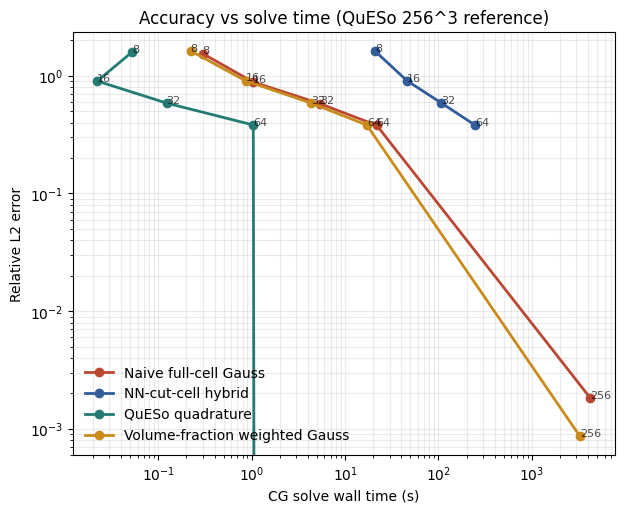

In [14]:
# --- Cell: timing vs accuracy -------------------------------------------------
timing_vs_accuracy = convergence_df.merge(
    timing_df[timing_df["status"] == "converged"][["framework", "resolution", "solve_seconds"]],
    on=["framework", "resolution"], how="inner",
)

figure, axis = plt.subplots(figsize=(7, 5.5))
for framework, curve in timing_vs_accuracy.groupby("framework", sort=False):
    curve = curve.sort_values("resolution")
    axis.loglog(curve["solve_seconds"], curve["relative_l2_error"], marker="o", linewidth=2,
                color=FRAMEWORK_COLORS[framework], label=curve["framework_label"].iloc[0])
    for _, row in curve.iterrows():
        axis.annotate(str(row["resolution"]), (row["solve_seconds"], row["relative_l2_error"]), fontsize=8, alpha=0.7)

axis.set(title=f"Accuracy vs solve time (QuESo {REFERENCE_RESOLUTION}^3 reference)",
          xlabel="CG solve wall time (s)", ylabel="Relative L2 error")
axis.grid(True, which="both", alpha=0.25)
axis.legend(frameon=False)
figure.savefig(LOCAL_RESULTS_DIR / f"timing_vs_accuracy_{REFERENCE_RESOLUTION}_local.png", dpi=150, bbox_inches="tight")
plt.show()

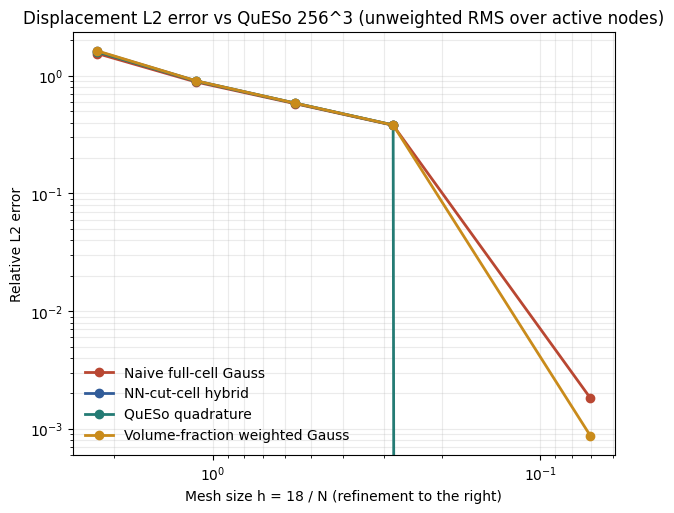

In [13]:
# --- Cell: convergence plot --------------------------------------------------
import matplotlib.pyplot as plt

figure, axis = plt.subplots(figsize=(7, 5.5))
for framework, curve in convergence_df.groupby("framework", sort=False):
    curve = curve.sort_values("h", ascending=False)
    axis.loglog(curve["h"], curve["relative_l2_error"], marker="o", linewidth=2,
                color=FRAMEWORK_COLORS[framework], label=curve["framework_label"].iloc[0])

axis.invert_xaxis()
axis.set(title=f"Displacement L2 error vs QuESo {REFERENCE_RESOLUTION}^3 (unweighted RMS over active nodes)",
          xlabel="Mesh size h = 18 / N (refinement to the right)", ylabel="Relative L2 error")
axis.grid(True, which="both", alpha=0.25)
axis.legend(frameon=False)
figure.savefig(LOCAL_RESULTS_DIR / f"convergence_vs_queso_{REFERENCE_RESOLUTION}_local.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
# --- Cell 9: merged timing table ---------------------------------------------
import pandas as pd

timing_frames = []
for name in JOBS:
    path = LOCAL_RESULTS_DIR / "smooth_foundation" / f"timing_{name}.csv"
    if path.is_file():
        timing_frames.append(pd.read_csv(path))
    else:
        print(f"(no timing file yet for {name}: {path})")

if timing_frames:
    timing_df = pd.concat(timing_frames, ignore_index=True).sort_values(["resolution", "framework"])
    display(timing_df)
else:
    print("No timing data pulled back yet -- run cell 8 after the jobs have made progress.")

,job_tag,gpu,framework,resolution,problem_build_seconds,boundary_term_seconds,status,cg_iterations,converged,full_cells,cut_cells,active_dofs,solve_seconds,timestamp
3,gpu1_rest,1,naive,8,27.7856,0.0013,converged,NaN,True,80,200,2187,0.2978,2026-08-26T13:15:39
6,gpu1_rest,1,nn,8,27.7856,0.0013,converged,NaN,True,80,200,2187,21.0484,2026-08-26T13:15:39
5,gpu1_rest,1,queso,8,27.7856,0.0013,converged,NaN,True,80,200,2187,0.0526,2026-08-26T13:15:39
4,gpu1_rest,1,weighted,8,27.7856,0.0013,converged,NaN,True,80,200,2187,0.2219,2026-08-26T13:15:39
7,gpu1_rest,1,naive,16,55.8860,0.0039,converged,NaN,True,864,800,14739,1.0309,2026-08-26T13:16:58
10,gpu1_rest,1,nn,16,55.8860,0.0039,converged,NaN,True,864,800,14739,46.0966,2026-08-26T13:17:00
9,gpu1_rest,1,queso,16,55.8860,0.0039,converged,NaN,True,864,800,14739,0.0222,2026-08-26T13:17:00
8,gpu1_rest,1,weighted,16,55.8860,0.0039,converged,NaN,True,864,800,14739,0.8600,2026-08-26T13:16:59
11,gpu1_rest,1,naive,32,62.5642,0.0227,converged,NaN,True,8264,3248,107811,5.3509,2026-08-26T13:18:50
14,gpu1_rest,1,nn,32,62.5642,0.0227,converged,NaN,True,8264,3248,107811,107.4356,2026-08-26T13:19:00


In [6]:
# --- Cell 9b: compute timing statistics -------------------------------------
# Turns the raw per-(framework, resolution) solve_seconds into what you
# actually care about: total wall time per resolution (build + boundary terms
# + all four solves), each framework's speed relative to QuESo, and a running
# cumulative total per job -- useful for estimating how much longer the
# still-running 512^3 job has left.

if timing_frames:
    # problem_build_seconds / boundary_term_seconds are identical across every
    # framework row for a given (job_tag, resolution) -- computed once and
    # shared -- so take the first value rather than summing.
    resolution_summary = (
        timing_df.groupby(["job_tag", "gpu", "resolution"])
        .agg(
            frameworks_completed=("status", lambda s: (s == "converged").sum()),
            frameworks_attempted=("framework", "count"),
            problem_build_seconds=("problem_build_seconds", "first"),
            boundary_term_seconds=("boundary_term_seconds", "first"),
            solve_seconds_total=("solve_seconds", "sum"),
        )
        .reset_index()
    )
    resolution_summary["total_seconds"] = (
        resolution_summary["problem_build_seconds"]
        + resolution_summary["boundary_term_seconds"]
        + resolution_summary["solve_seconds_total"]
    )
    resolution_summary = resolution_summary.sort_values("resolution")
    print("Wall time per resolution (build + boundary terms + all attempted solves):")
    display(
        resolution_summary.style.format({
            "problem_build_seconds": "{:.1f}s",
            "boundary_term_seconds": "{:.1f}s",
            "solve_seconds_total": "{:.1f}s",
            "total_seconds": "{:.1f}s",
        })
    )

    # Relative speed of each framework vs QuESo at the same resolution
    # (>1 = slower than QuESo, <1 = faster). QuESo is the natural baseline
    # since it's the reference-quality quadrature everything else is judged
    # against for accuracy.
    converged = timing_df[timing_df["status"] == "converged"]
    if "queso" in converged["framework"].unique():
        speedup = converged.pivot_table(index="resolution", columns="framework", values="solve_seconds", aggfunc="first").sort_index()
        relative = speedup.div(speedup["queso"], axis=0)
        print("\nSolve time relative to QuESo (1.00 = same speed, >1 = slower):")
        display(relative.style.format("{:.2f}x"))
    else:
        print("\n(QuESo hasn't converged at any resolution yet -- skipping relative-speed table.)")

    # Cumulative wall time per job in completion order -- the last value is
    # "how long has this GPU been running", and the slope gives a rough
    # per-resolution rate to extrapolate an ETA for whatever's still pending.
    cumulative = converged.sort_values("timestamp").copy()
    cumulative["cumulative_seconds"] = cumulative.groupby("job_tag")["solve_seconds"].cumsum()
    print("\nCumulative converged-solve time per job (most recent 10 rows):")
    display(
        cumulative[["job_tag", "resolution", "framework", "solve_seconds", "cumulative_seconds", "timestamp"]]
        .tail(10)
        .style.format({"solve_seconds": "{:.1f}s", "cumulative_seconds": "{:.1f}s"})
    )
else:
    print("Run the merged timing cell above first once timing data is available.")

Wall time per resolution (build + boundary terms + all attempted solves):


,job_tag,gpu,resolution,frameworks_completed,frameworks_attempted,problem_build_seconds,boundary_term_seconds,solve_seconds_total,total_seconds
1,gpu1_rest,1,8,4,4,27.8s,0.0s,21.6s,49.4s
2,gpu1_rest,1,16,4,4,55.9s,0.0s,48.0s,103.9s
3,gpu1_rest,1,32,4,4,62.6s,0.0s,117.2s,179.8s
4,gpu1_rest,1,64,4,4,88.7s,0.2s,285.0s,373.9s
0,gpu0_512,0,256,3,3,631.4s,10.0s,7729.1s,8370.5s



Solve time relative to QuESo (1.00 = same speed, >1 = slower):


framework,naive,nn,queso,weighted
resolution,,,,
8,5.66x,400.16x,1.00x,4.22x
16,46.44x,2076.42x,1.00x,38.74x
32,43.68x,877.03x,1.00x,35.04x
64,20.95x,235.64x,1.00x,16.41x
256,16.91x,nanx,1.00x,12.96x



Cumulative converged-solve time per job (most recent 10 rows):


,job_tag,resolution,framework,solve_seconds,cumulative_seconds,timestamp
12,gpu1_rest,32,weighted,4.3s,79.3s,2026-08-26T13:18:55
14,gpu1_rest,32,nn,107.4s,186.7s,2026-08-26T13:19:00
13,gpu1_rest,32,queso,0.1s,186.8s,2026-08-26T13:19:00
15,gpu1_rest,64,naive,21.8s,208.6s,2026-08-26T13:22:18
16,gpu1_rest,64,weighted,17.1s,225.7s,2026-08-26T13:22:40
17,gpu1_rest,64,queso,1.0s,226.7s,2026-08-26T13:22:57
18,gpu1_rest,64,nn,245.1s,471.8s,2026-08-26T13:22:58
0,gpu0_512,256,naive,4233.4s,4233.4s,2026-08-27T08:39:26
1,gpu0_512,256,weighted,3245.4s,7478.8s,2026-08-27T09:50:09
2,gpu0_512,256,queso,250.3s,7729.1s,2026-08-27T10:44:24


## 6. (Optional) Convergence + timing plot

Once at least `queso` at 512^3 and all four frameworks at the smaller
resolutions have landed, this reproduces the L2/energy convergence plot from
the original notebook (cell 27's logic) plus a new timing-vs-resolution
panel, all from the locally pulled `.npz` archives -- no remote access
needed for this cell.

This cell depends on `clean_simulation` being importable *locally* (same
package the original notebook imports from) since it reuses
`build_hard_constraint_problem` etc. to build the reference operator for the
energy norm. If your local machine doesn't have the repo, run the equivalent
analysis cell remotely instead (copy cell 27's logic into a small script the
same way `run_study.py` was built) and just pull back the resulting PNG/CSV
via cell 8's mechanism.


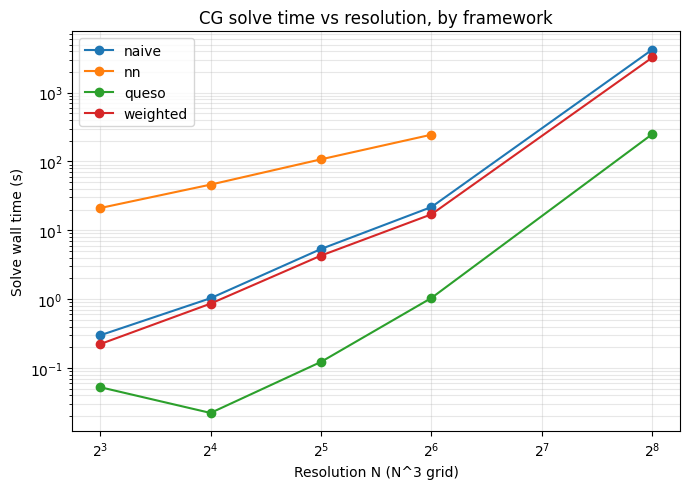

Saved C:\Users\z0058p1u\Documents\code\clean_simulation\notebooks\aws_pilot_results\timing_vs_resolution.png


In [7]:
# --- Cell 10: local convergence + timing plot (needs local clean_simulation) --
import matplotlib.pyplot as plt

if timing_frames:
    fig, ax = plt.subplots(figsize=(7, 5))
    for framework, group in timing_df.groupby("framework"):
        group = group.sort_values("resolution")
        ax.plot(group["resolution"], group["solve_seconds"], marker="o", label=framework)
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xlabel("Resolution N (N^3 grid)")
    ax.set_ylabel("Solve wall time (s)")
    ax.set_title("CG solve time vs resolution, by framework")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(LOCAL_RESULTS_DIR / "timing_vs_resolution.png", dpi=150)
    plt.show()
    print(f"Saved {LOCAL_RESULTS_DIR / 'timing_vs_resolution.png'}")
else:
    print("Run cell 9 first once timing data is available.")

# NOTE: for the full L2/energy-norm convergence plot (equivalent to the
# original notebook's cell 27), adapt that cell's code here, pointing
# ANALYSIS_DIR at LOCAL_RESULTS_DIR and ANALYSIS_REFERENCE_RESOLUTION at 512.
# It is not inlined here because it needs the local clean_simulation package
# to rebuild the reference operator for the energy norm -- ask me to fill
# this in once you confirm local imports work, or I can add a remote-side
# equivalent that writes the PNG/CSV directly on the instance instead.
